# 04 · Quantização e TensorFlow Lite

**Ementa 04** · Um modelo Keras guarda cada peso como `float32` e depende do TensorFlow inteiro (≈ 1 GB instalado). No Raspberry Pi queremos
um arquivo pequeno, um runtime leve e aritmética barata. O caminho: converter para o formato **TensorFlow Lite** (`.tflite`, executado pelo
**LiteRT**, o sucessor do `tflite-runtime`) e **quantizar** — representar pesos e ativações com inteiros de 8 bits.

Neste notebook você vai: **(1)** entender a quantização afim (`scale`, `zero_point`); **(2)** converter o modelo de RD em quatro níveis
(float32, float16, faixa dinâmica, int8 inteiro); **(3)** medir tamanho, erro, AUC e latência de cada um; **(4)** ver por que a versão *Lite* existe;
**(5)** escolher a arquitetura de cada tarefa e **exportar os modelos de triagem** para `modelos/`.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json, time
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from retina_iae import conversao as C, dados as D, inferencia as I, metricas as Me, modelos as M, treino as T, visualizacao as V

V.configurar_estilo()
cache = D.Cache()
ARQS = ["mobilenetv3_small", "efficientnet_lite0"]
faltando = [f"{t}_{a}" for t in D.TAREFAS for a in ARQS if not T.caminho_keras(t, a).exists()]
assert not faltando, f"rode o notebook 03 antes: faltam {faltando}"

## 1. Quantização afim em uma conta

Um valor real *x* numa faixa [mín, máx] vira um inteiro de 8 bits *q*:

$$q = \mathrm{round}\!\left(\frac{x}{\text{scale}}\right) + \text{zero\_point}, \qquad x \approx (q - \text{zero\_point})\cdot \text{scale}, \qquad
\text{scale} = \frac{\text{máx} - \text{mín}}{255}$$

O erro máximo é meio passo (scale/2). Para os **pesos**, a faixa é conhecida (os próprios pesos; no TFLite, uma escala **por canal** de saída).
Para as **ativações**, a faixa depende das imagens — por isso a quantização inteira precisa de um **conjunto representativo**: o conversor roda
o modelo em algumas imagens de treino e registra mín./máx. de cada tensor.

primeira conv: 432 pesos em [-1.162, 1.510] · scale = 0.01048 · zero_point = -17
erro máximo = 0.00520 (≤ scale/2 = 0.00524) · erro médio relativo = 0.88%


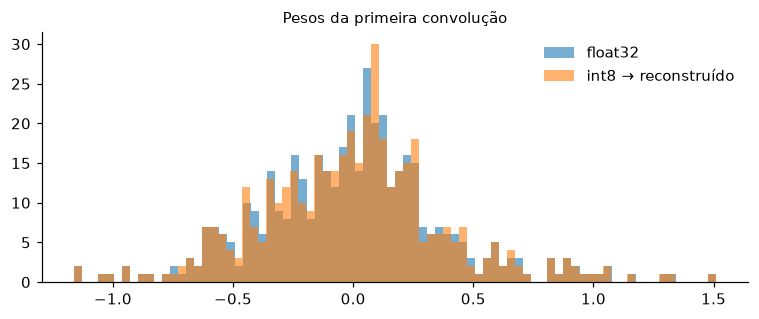

In [2]:
modelo_rd = T.carregar("rd", "mobilenetv3_small")
w = next(c for c in M.obter_base(modelo_rd).layers if isinstance(c, keras.layers.Conv2D)).get_weights()[0]
wmin, wmax = w.min(), w.max()
scale = (wmax - wmin) / 255; zp = int(round(-wmin / scale)) - 128          # int8: [-128, 127]
q = np.clip(np.round(w / scale) + zp, -128, 127)
w_rec = (q - zp) * scale
print(f"primeira conv: {w.size} pesos em [{wmin:.3f}, {wmax:.3f}] · scale = {scale:.5f} · zero_point = {zp}")
print(f"erro máximo = {np.abs(w - w_rec).max():.5f} (≤ scale/2 = {scale / 2:.5f}) · erro médio relativo = {np.abs(w - w_rec).mean() / np.abs(w).mean():.2%}")
fig, ax = plt.subplots(figsize=(7, 3)); ax.hist(w.ravel(), bins=80, alpha=0.6, label="float32"); ax.hist(w_rec.ravel(), bins=80, alpha=0.6, label="int8 → reconstruído")
ax.legend(frameon=False); ax.set_title("Pesos da primeira convolução"); fig.tight_layout(); plt.show()

## 2. Quatro conversões do mesmo modelo

`retina_iae.conversao.converter` exporta um *SavedModel* com **lote fixo 1** (como no dispositivo) e chama o `TFLiteConverter`:

| modo | o que muda | precisa de dados? |
|---|---|---|
| `float32` | só o formato | não |
| `float16` | pesos em 16 bits (convertidos de volta para 32 na execução em CPU) | não |
| `dinamica` | pesos int8; ativações quantizadas "na hora", por lote | não |
| `int8` | pesos **e** ativações int8; entrada **uint8** (a imagem crua!) | sim — 200 imagens do treino |

In [3]:
Xtr, ytr, _ = D.conjunto("rd", "treino", cache)
Xva, yva, _ = D.conjunto("rd", "validacao", cache)
rep = C.dados_representativos(Xtr, n=200)
pasta_comp = D.MODELOS / "comparacao"
tflites, linhas = {}, []
for arq in ARQS:
    mk = T.carregar("rd", arq)
    p_keras = T.prever(mk, Xva)
    for modo in C.MODOS:
        t0 = time.time()
        conteudo = C.converter(mk, modo, rep if modo == "int8" else None)
        C.salvar_tflite(conteudo, pasta_comp / f"rd_{arq}_{modo}.tflite")
        mt = I.ModeloTFLite(conteudo, threads=4)
        p = mt.prever(Xva)
        lat = mt.medir_latencia(Xva[:1], repeticoes=50)
        tflites[(arq, modo)] = conteudo
        linhas.append({"arquitetura": arq, "modo": modo, "tamanho (MB)": len(conteudo) / 1e6, "entrada": mt.tipo_entrada.name,
                       "XNNPACK": mt.xnnpack, "máx |Δp| vs Keras": np.abs(p - p_keras).max(), "AUC validação": Me.auc(yva, p),
                       "Δ AUC vs Keras": Me.auc(yva, p) - Me.auc(yva, p_keras), "latência PC (ms)": lat["mediana_ms"],
                       "conversão (s)": time.time() - t0})
quant = pd.DataFrame(linhas).set_index(["arquitetura", "modo"])
quant.round({"tamanho (MB)": 2, "máx |Δp| vs Keras": 4, "AUC validação": 4, "Δ AUC vs Keras": 4, "latência PC (ms)": 2, "conversão (s)": 1})

tamanho (MB)  entrada  XNNPACK  \
arquitetura        modo                                       
mobilenetv3_small  float32           3.76  float32     True   
                   float16           1.95  float32     True   
                   dinamica          1.13  float32     True   
                   int8              1.24    uint8    False   
efficientnet_lite0 float32          13.46  float32     True   
                   float16           6.79  float32     True   
                   dinamica          3.73  float32     True   
                   int8              3.98    uint8     True   

                             máx |Δp| vs Keras  AUC validação  Δ AUC vs Keras  \
arquitetura        modo                                                         
mobilenetv3_small  float32              0.0000         0.9858          0.0000   
                   float16              0.0128         0.9857         -0.0001   
                   dinamica             0.3867         0.9870          0.0012   
                   int8                 0.7731         0.9587         -0.0270   
efficientnet_lite0 float32              0.0000         0.9882          0.0000   
                   float16              0.0126         0.9882          0.0000   
                   dinamica             0.0717         0.9881         -0.0001   
                   int8                 0.1698         0.9888          0.0006   

                             latência PC (ms)  conversão (s)  
arquitetura        modo                                       
mobilenetv3_small  float32               1.72            8.5  
                   float16               1.52            9.4  
                   dinamica              5.33           21.0  
                   int8                117.85           76.4  
efficientnet_lite0 float32               5.03           11.1  
                   float16               4.92           11.0  
                   dinamica             62.84           44.4  
                   int8                  3.19           23.3

O que a tabela mostra (os números exatos estão acima):

* **float32** reproduz o Keras (Δ = 0): a conversão em si não muda nada. **float16** corta o arquivo pela metade com erro desprezível (Δp ≈ 0,01).
* **EfficientNet-Lite0 int8:** arquivo ≈ 3,4× menor que o float32, **a AUC não muda** e a latência **cai** (≈ 3 ms contra ≈ 5 ms) — roda no **XNNPACK**,
  o acelerador de CPU padrão do LiteRT (x86 e ARM), com aritmética inteira.
* **MobileNetV3-Small int8: `XNNPACK = False`.** O XNNPACK **recusa** o grafo int8 do MobileNetV3 (blocos *squeeze-and-excitation* e *hard-swish*
  quantizados) e o LiteRT cai para os kernels de referência: a inferência fica **dezenas de vezes mais lenta que o próprio float32**. E o erro de
  quantização é grande — a probabilidade de uma imagem muda até ≈ 0,8 e a AUC cai ≈ 0,03. O modelo "menor" no papel é o **pior** no dispositivo.
* **Faixa dinâmica** (pesos int8, ativações quantizadas em tempo de execução) é a opção sem dados de calibração — e aqui é a **mais lenta** das
  quatro: quantizar ativações a cada camada, em CPU x86, custa mais do que economiza. O formato certo depende do runtime e do processador.
* A versão *Lite* do EfficientNet tirou o SE e o swish exatamente para isto: quantizar bem e rodar nos aceleradores. **A arquitetura tem de ser
  escolhida pensando no formato final.**
* Latência no PC não é latência no Pi (notebook 05), mas a **ordem** costuma se manter — confira na sessão presencial.

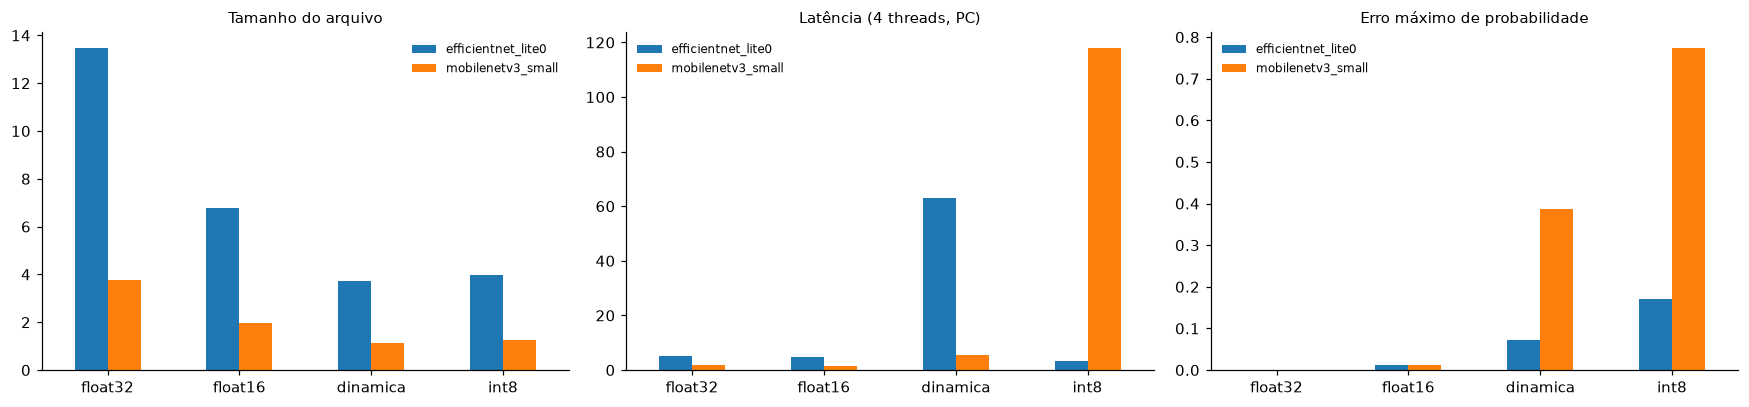

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, titulo in zip(axs, ["tamanho (MB)", "latência PC (ms)", "máx |Δp| vs Keras"], ["Tamanho do arquivo", "Latência (4 threads, PC)", "Erro máximo de probabilidade"]):
    quant[col].unstack(0).loc[list(C.MODOS)].plot.bar(ax=ax, rot=0); ax.set_title(titulo); ax.set_xlabel(""); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); V.salvar_figura(fig, "04_quantizacao"); plt.show()

### Por dentro do `.tflite` int8

`get_input_details()` diz exatamente o que o modelo espera — é esta informação, e não uma suposição, que o código do dispositivo deve seguir:

In [5]:
for arq in ARQS:
    mt = I.ModeloTFLite(tflites[(arq, "int8")])
    print(arq, mt.descrever())
it = I.ModeloTFLite(tflites[("efficientnet_lite0", "int8")]).interp
ops = pd.Series([d["op_name"] for d in it._get_ops_details()]).value_counts()
print("\noperadores do EfficientNet-Lite0 int8:", dict(ops))

mobilenetv3_small {'arquivo': '(memória)', 'tamanho_MB': 1.24008, 'entrada': '(1, 224, 224, 3) uint8', 'entrada_scale_zp': (1.0, 0), 'saida': '(1, 1) float32', 'saida_scale_zp': (0.0, 0), 'runtime': 'ai_edge_litert', 'xnnpack': False, 'threads': 4}
efficientnet_lite0 {'arquivo': '(memória)', 'tamanho_MB': 3.979, 'entrada': '(1, 224, 224, 3) uint8', 'entrada_scale_zp': (1.0, 0), 'saida': '(1, 1) float32', 'saida_scale_zp': (0.0, 0), 'runtime': 'ai_edge_litert', 'xnnpack': True, 'threads': 4}

operadores do EfficientNet-Lite0 int8: {'CONV_2D': np.int64(33), 'DEPTHWISE_CONV_2D': np.int64(16), 'ADD': np.int64(10), 'QUANTIZE': np.int64(1), 'MUL': np.int64(1), 'MEAN': np.int64(1), 'FULLY_CONNECTED': np.int64(1), 'LOGISTIC': np.int64(1), 'DEQUANTIZE': np.int64(1), 'DELEGATE': np.int64(1)}


Entrada **uint8 com scale = 1,0 e zero_point = 0**: o modelo recebe a imagem pré-processada do Módulo 02 **exatamente como ela é** (0–255).
Isso só é possível porque a normalização para [−1, 1] está **dentro** do modelo (notebook 00) e foi quantizada junto. Saída `float32`: P(condição).

### Quantas imagens de calibração?

In [6]:
mk = T.carregar("rd", "efficientnet_lite0"); p_keras = T.prever(mk, Xva)
linhas = []
for n in [1, 10, 50, 200, 500]:
    mt = I.ModeloTFLite(C.converter(mk, "int8", C.dados_representativos(Xtr, n=n, semente=1)))
    p = mt.prever(Xva)
    linhas.append({"imagens de calibração": n, "máx |Δp|": np.abs(p - p_keras).max(), "média |Δp|": np.abs(p - p_keras).mean(), "AUC validação": Me.auc(yva, p)})
pd.DataFrame(linhas).set_index("imagens de calibração").round(4)

,máx |Δp|,média |Δp|,AUC validação
imagens de calibração,,,
1,0.5000,0.3680,0.9669
10,0.1737,0.0082,0.9887
50,0.1698,0.0083,0.9882
200,0.2110,0.0090,0.9887
500,0.1894,0.0089,0.9885


Com uma única imagem as faixas das ativações ficam erradas: o erro médio é ≈ 40× maior e a AUC cai; a partir de ≈ 10 imagens, estabiliza. Usamos 200 imagens **do treino**
(nunca da validação/teste — elas seriam usadas para ajustar o modelo).

## 3. Escolha da arquitetura e exportação dos modelos de triagem

Convertemos os seis modelos (3 tarefas × 2 arquiteturas) para int8 e escolhemos, **pela validação**, a arquitetura de cada tarefa:

* critério principal: **AUC de validação do modelo int8** (o que de fato vai rodar);
* desempate (diferença < 0,01): o **mais leve** (MobileNetV3-Small) só se ele rodar com XNNPACK; senão, o Lite0.

O **limiar** de triagem também é escolhido na validação: o maior limiar com **sensibilidade ≥ 90 %** (perder um caso é pior que encaminhar um saudável —
decisão de projeto discutida no notebook 06).

In [7]:
SENS_ALVO = 0.90
candidatos, linhas = {}, []
for tarefa in D.TAREFAS:
    Xtr_t = D.conjunto(tarefa, "treino", cache)[0]
    Xva_t, yva_t, _ = D.conjunto(tarefa, "validacao", cache)
    for arq in ARQS:
        conteudo = C.converter(T.carregar(tarefa, arq), "int8", C.dados_representativos(Xtr_t, n=200))
        mt = I.ModeloTFLite(conteudo, threads=4)
        p = mt.prever(Xva_t)
        candidatos[(tarefa, arq)] = (conteudo, p)
        linhas.append({"tarefa": tarefa, "arquitetura": arq, "AUC val int8": Me.auc(yva_t, p), "XNNPACK": mt.xnnpack,
                       "latência PC (ms)": mt.medir_latencia(Xva_t[:1])["mediana_ms"], "tamanho (MB)": len(conteudo) / 1e6})
selecao = pd.DataFrame(linhas)

def escolher(g):
    g = g.set_index("arquitetura")
    melhor = g["AUC val int8"].idxmax()
    leve = "mobilenetv3_small"
    if melhor != leve and g.loc[melhor, "AUC val int8"] - g.loc[leve, "AUC val int8"] < 0.01 and g.loc[leve, "XNNPACK"]:
        return leve
    return melhor

escolhas = {t: escolher(g) for t, g in selecao.groupby("tarefa")}
selecao["escolhida"] = [escolhas[t] == a for t, a in zip(selecao.tarefa, selecao.arquitetura)]
selecao.set_index(["tarefa", "arquitetura"]).round(3)

AUC val int8  XNNPACK  latência PC (ms)  \
tarefa   arquitetura                                                   
rd       mobilenetv3_small          0.959    False           101.486   
         efficientnet_lite0         0.989     True             3.215   
glaucoma mobilenetv3_small          0.883    False            97.474   
         efficientnet_lite0         0.916     True             3.199   
dmri     mobilenetv3_small          0.873    False            95.475   
         efficientnet_lite0         0.926     True             3.398   

                             tamanho (MB)  escolhida  
tarefa   arquitetura                                  
rd       mobilenetv3_small          1.240      False  
         efficientnet_lite0         3.979       True  
glaucoma mobilenetv3_small          1.244      False  
         efficientnet_lite0         3.982       True  
dmri     mobilenetv3_small          1.241      False  
         efficientnet_lite0         3.980       True

In [8]:
cfg = {"versao": "1.0", "gerado_por": "notebooks/04_Quantizacao_e_TFLite.ipynb",
       "preprocessamento": {**{k: v for k, v in D.CONFIG_PRE.items()}, "funcao": "retina_pdi.pipeline.preparar_para_inferencia",
                            "retina_pdi_commit": "70d02c46d345eecb2313ebc6a6051ec33ac58aab"},
       "entrada": "uint8 (1, 224, 224, 3) RGB, sem normalização (feita dentro do modelo)",
       "criterio_limiar": f"maior limiar com sensibilidade >= {SENS_ALVO:.0%} na validação",
       "modelos": {}}
for tarefa in D.TAREFAS:
    arq = escolhas[tarefa]
    conteudo, p = candidatos[(tarefa, arq)]
    yva_t = D.conjunto(tarefa, "validacao", cache)[1]
    lim = Me.limiar_para_sensibilidade(yva_t, p, SENS_ALVO)
    arquivo = f"{tarefa}_{arq}_int8.tflite"
    C.salvar_tflite(conteudo, D.MODELOS / arquivo)
    m_val = Me.metricas_no_limiar(yva_t, p, lim)
    cfg["modelos"][tarefa] = {"nome": D.NOMES_CONDICAO[tarefa] + (" referível" if tarefa == "rd" else ""), "arquivo": arquivo,
                              "arquitetura": arq, "quantizacao": "int8 (entrada uint8, saída float32)", "limiar": round(lim, 4),
                              "validacao": {"AUC": round(Me.auc(yva_t, p), 4), "sensibilidade": round(m_val["sensibilidade"], 4),
                                            "especificidade": round(m_val["especificidade"], 4)}}
(D.MODELOS / "config_triagem.json").write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({t: {k: v for k, v in m.items() if k in ("arquivo", "limiar", "validacao")} for t, m in cfg["modelos"].items()}, indent=1, ensure_ascii=False))

{
 "rd": {
  "arquivo": "rd_efficientnet_lite0_int8.tflite",
  "limiar": 0.7812,
  "validacao": {
   "AUC": 0.9888,
   "sensibilidade": 0.9013,
   "especificidade": 0.9601
  }
 },
 "glaucoma": {
  "arquivo": "glaucoma_efficientnet_lite0_int8.tflite",
  "limiar": 0.332,
  "validacao": {
   "AUC": 0.9161,
   "sensibilidade": 0.9024,
   "especificidade": 0.693
  }
 },
 "dmri": {
  "arquivo": "dmri_efficientnet_lite0_int8.tflite",
  "limiar": 0.0938,
  "validacao": {
   "AUC": 0.9264,
   "sensibilidade": 0.9048,
   "especificidade": 0.8014
  }
 }
}


Os três `.tflite` e o `config_triagem.json` ficam em `modelos/` e são **versionados no Git**: é deles que o Raspberry Pi precisa (notebook 05).
`modelos/comparacao/` guarda o modelo de RD nos quatro modos, para repetir a comparação de latência no Pi.

### Conferência final: o modelo exportado roda sem TensorFlow

`retina_iae.triagem.Triagem` só usa o LiteRT e o `retina_pdi`. Uma captura **bruta** (não o tensor do cache) passa pelo fluxo completo:

In [9]:
from retina_iae.triagem import Triagem
tri = Triagem()
linha = D.carregar_manifesto().query("fonte == 'DDR' and grau == '3'").iloc[0]
r = tri.avaliar(D.carregar_rgb(linha.arquivo))
print(f"{linha.id} (DDR, grau {linha.grau}) — {r.tempos_ms['total']:.0f} ms no total\n")
print(tri.laudo(r))

ddr_007-5520-300 (DDR, grau 3) — 143 ms no total

  Retinopatia diabética referível            ENCAMINHAR               (escore 0.99; limiar 0.78)
  Glaucoma                                   sem alteração detectada  (escore 0.03; limiar 0.33)
  DMRI                                       ENCAMINHAR               (escore 0.89; limiar 0.09)
→ Encaminhar ao oftalmologista.
Resultado de TRIAGEM automatizada, não é diagnóstico. A decisão clínica cabe ao oftalmologista (protótipo de pesquisa — Edital FACEPE nº 14/2026).


Repare no laudo: uma retina com **RD grau 3** também foi encaminhada por **DMRI**. Cada modelo foi treinado contra imagens **normais** —
nenhum viu outras doenças como negativas —, então a especificidade de um modelo diante das outras condições **não foi medida**. Na prática, um
encaminhamento significa "retina alterada"; quem diz qual é a doença é o oftalmologista. Voltamos a isso nos erros do notebook 06.

## Resumo

| | float32 | float16 | dinâmica | int8 |
|---|---|---|---|---|
| tamanho | 1× | ½ | ≈ ¼ | ≈ ¼ |
| precisa calibrar | não | não | não | sim (≈ 200 imagens de treino) |
| entrada | float32 | float32 | float32 | **uint8** (imagem direto) |
| aqui (PC, LiteRT) | referência | igual ao float32 | **lenta** | **mais rápida** (Lite0) · muito lenta (MobileNetV3) |
| quando usar | referência / depuração | GPU móvel | sem dados de calibração, se o runtime a acelerar | **CPU ARM com XNNPACK, NPU/TPU (Coral, Hailo)** |

E a lição de arquitetura: **escolha o modelo pensando no formato final**. Um modelo ótimo em float32 que não roda no acelerador depois de quantizado
é um modelo pior no dispositivo.

## Exercícios propostos

1. **MobileNetV3 "minimalista".** Treine a tarefa RD com `MobileNetV3Small(minimalistic=True)` (sem SE nem hard-swish), quantize e verifique:
   ele roda com XNNPACK? Qual o erro de quantização?
2. **Calibração enviesada.** Calibre o int8 só com imagens **negativas** (ou só de uma câmera). O que acontece com o erro e com a AUC na validação?
   E no DDR?
3. **Quantização por camada.** Use `tf.lite.experimental.QuantizationDebugger` para encontrar as camadas com maior erro no MobileNetV3 int8.
   São as do SE?
4. **Treino ciente da quantização (QAT).** Pesquise o `tensorflow_model_optimization` e discuta: em que situação o QAT valeria o esforço aqui?
5. **Threads.** Repita a medição de latência com `threads` = 1, 2, 4 e 8. O ganho é linear? Por quê?